<a href="https://colab.research.google.com/github/yumin9931-collab/-/blob/main/%EA%B8%88%EC%9C%B5%ED%86%B5%EA%B3%84%20%EA%B8%B0%EB%A7%90%202%EC%B0%A8%20%EC%B4%88%EC%95%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

2차 과제

In [31]:
# FinanceDataReader가 설치되어 있지 않다면 설치합니다.
!pip install -q finance-datareader

import FinanceDataReader as fdr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (코랩 환경)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

In [32]:
# 기간 설정: 2024년 5월 1일 ~ 2026년 11월 16일 (약 2년 반)
start_date = '2024-05-01'
end_date = '2026-11-16'

# 종목 코드 정의
tickers = {
    'NAVER': '035420',
    'Kakao': '035720'
}

# 대략적인 상장 주식수 (발행주식총수 기준, 단위: 주)
# ※ 정확한 분석 시점의 정확한 주식수를 반영하려면 DART 등을 참고할 수 있습니다.
shares = {
    'NAVER': 148157793,
    'Kakao': 443468536
}

df_list = []
for name, code in tickers.items():
    df = fdr.DataReader(code, start_date, end_date)
    # 시가총액 계산 (종가 * 상장주식수 / 1조원 단위로 환산)
    df['MarketCap_Trillion'] = (df['Close'] * shares[name]) / 1e12
    df['Company'] = name
    df_list.append(df[['Close', 'MarketCap_Trillion', 'Company']])

# 데이터 병합
df_all = pd.concat(df_list)
df_all.reset_index(inplace=True)

# 최근 데이터 확인
print(df_all.tail())

           Date  Close  MarketCap_Trillion Company
1229 2026-11-10  31800           14.102299   Kakao
1230 2026-11-11  32000           14.190993   Kakao
1231 2026-11-12  31850           14.124473   Kakao
1232 2026-11-13  31900           14.146646   Kakao
1233 2026-11-16  32450           14.390554   Kakao


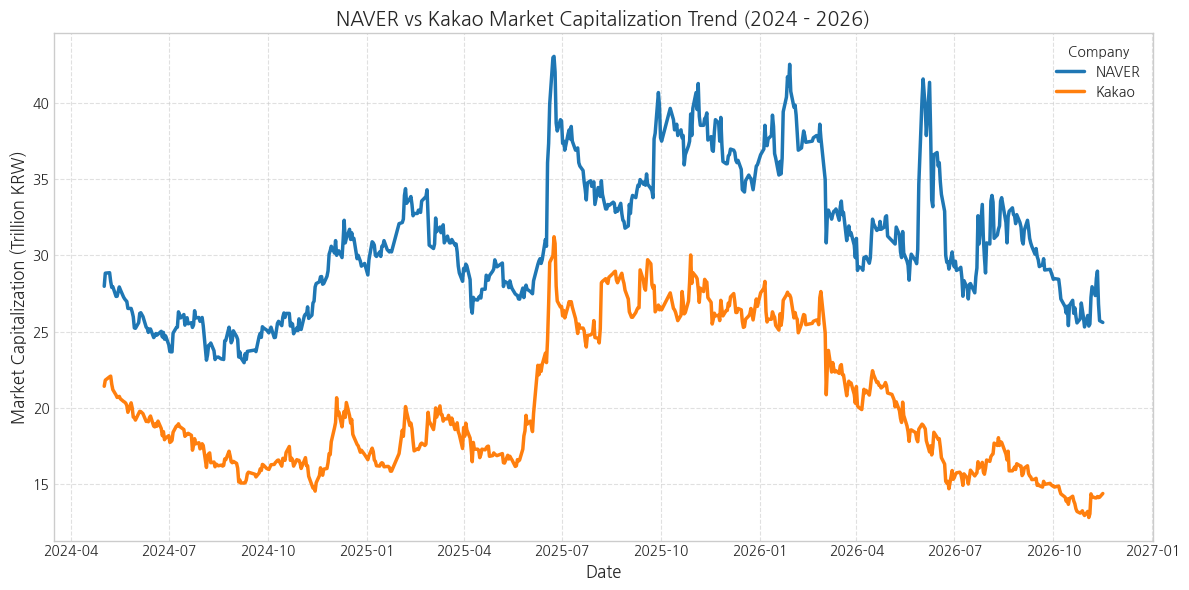

In [33]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_all, x='Date', y='MarketCap_Trillion', hue='Company', linewidth=2.5)

plt.title('NAVER vs Kakao Market Capitalization Trend (2024 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Market Capitalization (Trillion KRW)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

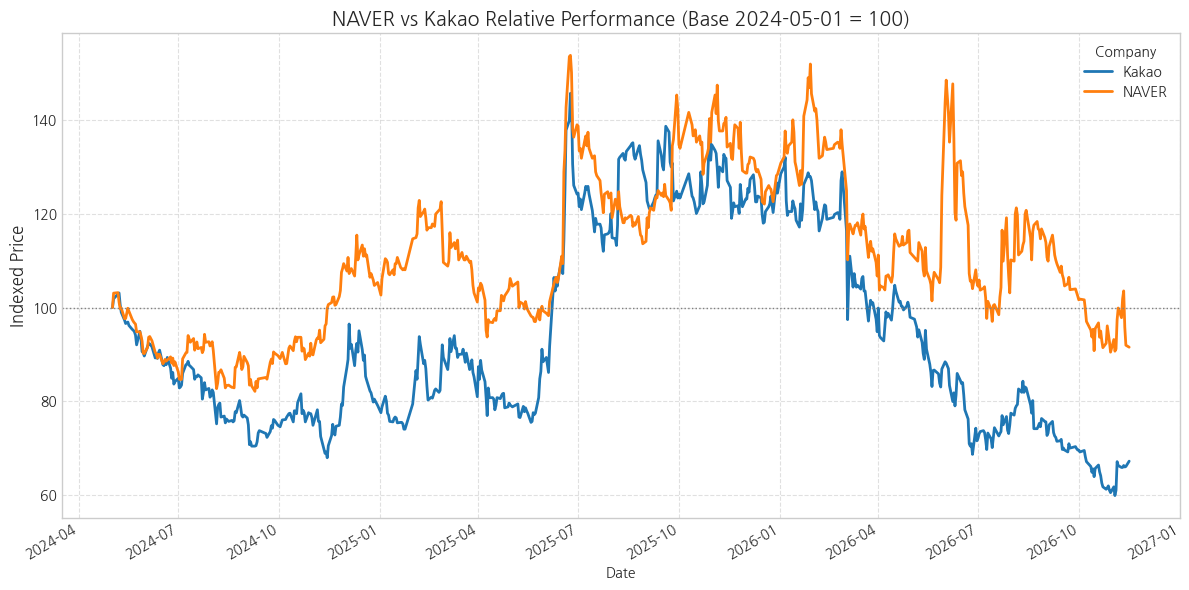

In [34]:
# 코스피 대비 상대 성과 비교
# 기준일(시작일) 대비 주가 상승률 비교
df_pivot = df_all.pivot(index='Date', columns='Company', values='Close')
df_indexed = (df_pivot / df_pivot.iloc[0]) * 100

plt.figure(figsize=(12, 6))
df_indexed.plot(ax=plt.gca(), linewidth=2)
plt.title('NAVER vs Kakao Relative Performance (Base 2024-05-01 = 100)', fontsize=14, fontweight='bold')
plt.ylabel('Indexed Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(100, color='gray', linestyle=':', linewidth=1)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

=== 전체 기간 연환산 수익률 변동성 ===
NAVER: 46.73%
Kakao: 46.38%


<Figure size 1200x600 with 0 Axes>

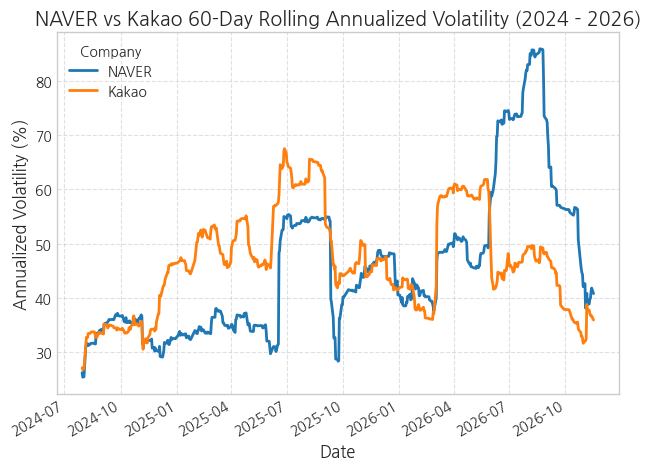

In [35]:
# 1. 라이브러리 설치 및 임포트
!pip install -q finance-datareader

import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 2년 반 데이터 수집 (2024-05-01 ~ 2026-11-16)
start_date = '2024-05-01'
end_date = '2026-11-16'

tickers = {'NAVER': '035420', 'Kakao': '035720'}
df_prices = pd.DataFrame()

for name, code in tickers.items():
  df = fdr.DataReader(code, start_date, end_date)
  df_prices[name] = df['Close']

# 3. 일일 수익률(Percentage Change) 계산
df_returns = df_prices.pct_change().dropna()

# 4. 전체 기간 연환산 변동성 계산 (Standard Deviation * sqrt(252))
annual_volatility = df_returns.std() * np.sqrt(252)

print('=== 전체 기간 연환산 수익률 변동성 ===')
for name, vol in annual_volatility.items():
  print(f'{name}: {vol*100:.2f}%')

# 5. 60거래일(약 3개월) 롤링 연환산 변동성 시각화
# 시간 흐름에 따른 변동성 변화 추이를 확인합니다.
rolling_vol = df_returns.rolling(window=60).std() * np.sqrt(252) * 100

plt.figure(figsize=(12, 6))
rolling_vol.plot(linewidth=2)
plt.title(
    'NAVER vs Kakao 60-Day Rolling Annualized Volatility (2024 - 2026)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Annualized Volatility (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

In [36]:
# 필요한 라이브러리 설치 (arch 패키지는 GARCH 모형 추정에 사용됩니다)
!pip install -q finance-datareader arch

import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from arch import arch_model

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 데이터 수집 기간 설정 (2년 반: 2024-05-01 ~ 2026-11-16)
start_date = '2024-05-01'
end_date = '2026-11-16'

tickers = {'NAVER': '035420', 'Kakao': '035720'}
df_prices = pd.DataFrame()

for name, code in tickers.items():
  df = fdr.DataReader(code, start_date, end_date)
  df_prices[name] = df['Close']

# 일일 로그 수익률 계산 (연속복리 기준 또는 퍼센트 수익률)
# 금융시계열에서는 주로 log return을 사용합니다.
df_returns = np.log(df_prices / df_prices.shift(1)).dropna() * 100

<Figure size 1200x600 with 0 Axes>

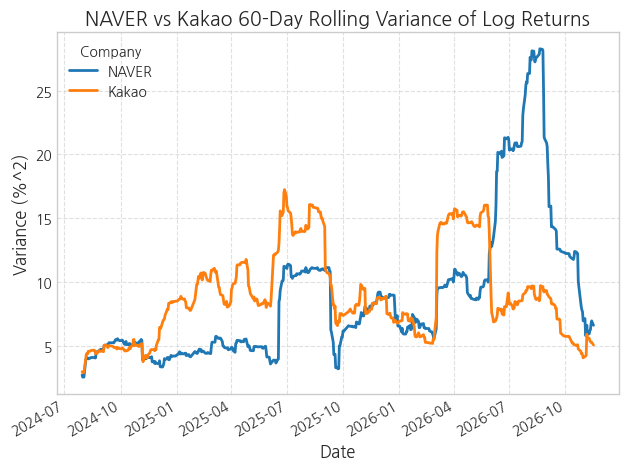

In [38]:
# 60거래일 롤링 분산 계산
window_size = 60
rolling_var = df_returns.rolling(window=window_size).var()

# 시각화
plt.figure(figsize=(12, 6))
rolling_var.plot(linewidth=2)
plt.title(
    'NAVER vs Kakao 60-Day Rolling Variance of Log Returns',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Variance (%^2)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

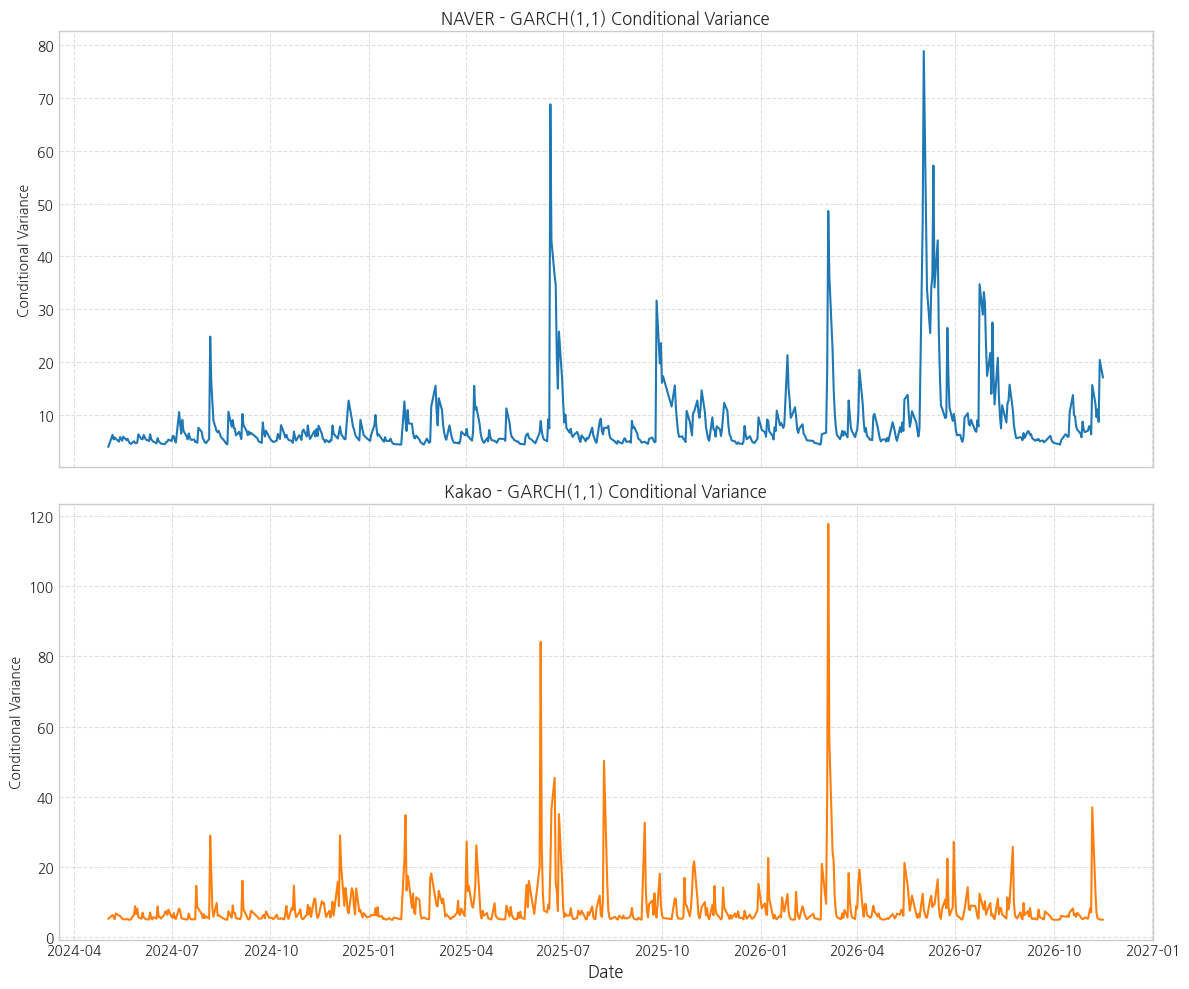

=== NAVER GARCH Summary ===
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  NAVER   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1485.05
Distribution:                  Normal   AIC:                           2978.09
Method:            Maximum Likelihood   BIC:                           2995.78
                                        No. Observations:                  616
Date:                Mon, Nov 16 2026   Df Residuals:                      615
Time:                        05:33:22   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0.0429  9.669e-02     -0.44

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for i, name in enumerate(['NAVER', 'Kakao']):
  # GARCH(1,1) 모형 적합 (평균방정식: 상수, 분산방정식: GARCH(1,1))
  model = arch_model(df_returns[name], mean='Constant', vol='GARCH', p=1, q=1)
  results = model.fit(disp='off')

  # 조건부 분산(Conditional Variance) 추출
  conditional_var = results.conditional_volatility ** 2

  # 시각화
  axes[i].plot(
      conditional_var.index,
      conditional_var,
      color='tab:orange' if i == 1 else 'tab:blue',
      linewidth=1.5,
  )
  axes[i].set_title(
      f'{name} - GARCH(1,1) Conditional Variance',
      fontsize=12,
      fontweight='bold',
  )
  axes[i].set_ylabel('Conditional Variance', fontsize=10)
  axes[i].grid(True, linestyle='--', alpha=0.6)

plt.xlabel('Date', fontsize=12)
plt.tight_layout()
plt.show()

# GARCH 추정 결과 요약 출력
print('=== NAVER GARCH Summary ===')
print(
    arch_model(df_returns['NAVER'], vol='GARCH', p=1, q=1)
    .fit(disp='off')
    .summary()
)
print('\n=== Kakao GARCH Summary ===')
print(
    arch_model(df_returns['Kakao'], vol='GARCH', p=1, q=1)
    .fit(disp='off')
    .summary()
)

=== NAVER와 Kakao 일일 수익률 상관계수 비교 ===
• 전체 기간 상관계수: 0.5737
• 일반적인 날 (Normal Days) 상관계수: 0.5220
• 시장 충격일 (KOSPI 하위 10% 급락일) 상관계수: 0.6126
• 표본 수 - 전체: 616일, 정상일: 554일, 충격일: 62일


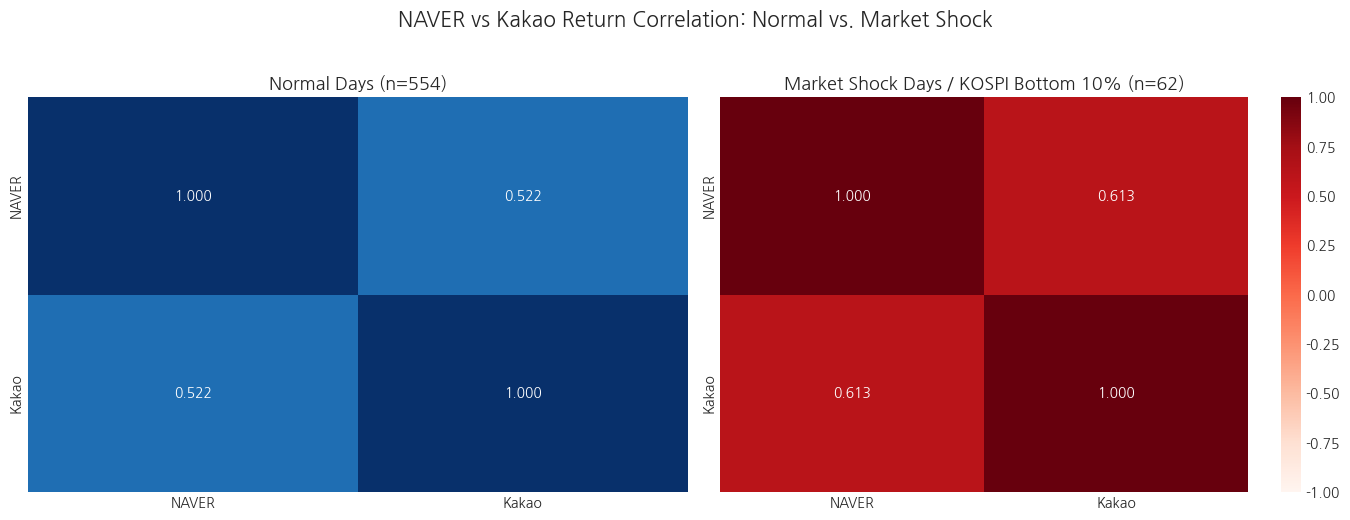

In [41]:
# 1. 라이브러리 설치 및 임포트
!pip install -q finance-datareader

import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 수집 (2년 반: 2024-05-01 ~ 2026-11-16)
start_date = '2024-05-01'
end_date = '2026-11-16'

tickers = {
    'NAVER': '035420',
    'Kakao': '035720',
    'KOSPI': 'KS11'  # 시장 벤치마크 지수
}

df_prices = pd.DataFrame()
for name, code in tickers.items():
    df = fdr.DataReader(code, start_date, end_date)
    df_prices[name] = df['Close']

# 결측치 제거 후 일일 수익률(Percentage Change) 계산
df_prices = df_prices.dropna()
df_returns = df_prices.pct_change().dropna()

# 3. 시장 충격일(Market Shock Day) 정의
# KOSPI 일일 수익률이 하위 10%에 해당하는 날을 시장 충격일로 정의합니다.
shock_threshold = df_returns['KOSPI'].quantile(0.10)

df_shock = df_returns[df_returns['KOSPI'] <= shock_threshold]
df_normal = df_returns[df_returns['KOSPI'] > shock_threshold]

# 4. 상관계수 산출 및 출력
corr_total = df_returns[['NAVER', 'Kakao']].corr().loc['NAVER', 'Kakao']
corr_shock = df_shock[['NAVER', 'Kakao']].corr().loc['NAVER', 'Kakao']
corr_normal = df_normal[['NAVER', 'Kakao']].corr().loc['NAVER', 'Kakao']

print(f"=== NAVER와 Kakao 일일 수익률 상관계수 비교 ===")
print(f"• 전체 기간 상관계수: {corr_total:.4f}")
print(f"• 일반적인 날 (Normal Days) 상관계수: {corr_normal:.4f}")
print(f"• 시장 충격일 (KOSPI 하위 10% 급락일) 상관계수: {corr_shock:.4f}")
print(f"• 표본 수 - 전체: {len(df_returns)}일, 정상일: {len(df_normal)}일, 충격일: {len(df_shock)}일")

# 5. 상관계수 히트맵 시각화 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 일반적인 날 히트맵
sns.heatmap(
    df_normal[['NAVER', 'Kakao']].corr(),
    annot=True, fmt='.3f', cmap='Blues', vmin=-1, vmax=1, ax=axes[0], cbar=False
)
axes[0].set_title(f'Normal Days (n={len(df_normal)})', fontsize=13, fontweight='bold')

# 시장 충격일 히트맵
sns.heatmap(
    df_shock[['NAVER', 'Kakao']].corr(),
    annot=True, fmt='.3f', cmap='Reds', vmin=-1, vmax=1, ax=axes[1]
)
axes[1].set_title(f'Market Shock Days / KOSPI Bottom 10% (n={len(df_shock)})', fontsize=13, fontweight='bold')

plt.suptitle('NAVER vs Kakao Return Correlation: Normal vs. Market Shock', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

=== 실적 발표일별 단기 주가 수익률 (%) ===
Earnings_Date Company  Return_T1  Return_T3  Return_T5
   2024-05-10   NAVER  -2.279958  -0.053022  -2.439024
   2024-05-10   Kakao  -1.673640  -2.092050  -3.661088
   2024-08-09   NAVER  -2.076970  -3.909591  -4.337202
   2024-08-09   Kakao   0.270270  -0.540541  -0.945946
   2024-11-08   NAVER   0.801833   4.352806   8.820160
   2024-11-08   Kakao  -3.714286  -4.571429  -2.714286
   2025-02-07   NAVER   0.886918  -0.221729  -1.995565
   2025-02-07   Kakao  -4.494382  -5.617978 -12.921348
   2025-05-09   NAVER  -0.418848   0.104712  -1.675393
   2025-05-09   Kakao   3.112314   2.706360   1.217862
   2025-08-08   NAVER  -2.832244  -1.960784  -1.525054
   2025-08-08   Kakao   0.626959  -0.470219   1.880878
   2025-11-06   NAVER  -1.515152  -0.378788   0.568182
   2025-11-06   Kakao   3.459638   5.601318   4.942339
   2026-02-06   NAVER   0.401606   3.413655   1.405622
   2026-02-06   Kakao   2.313167   4.804270   2.135231
   2026-05-08   NAVER  -1.627907  -

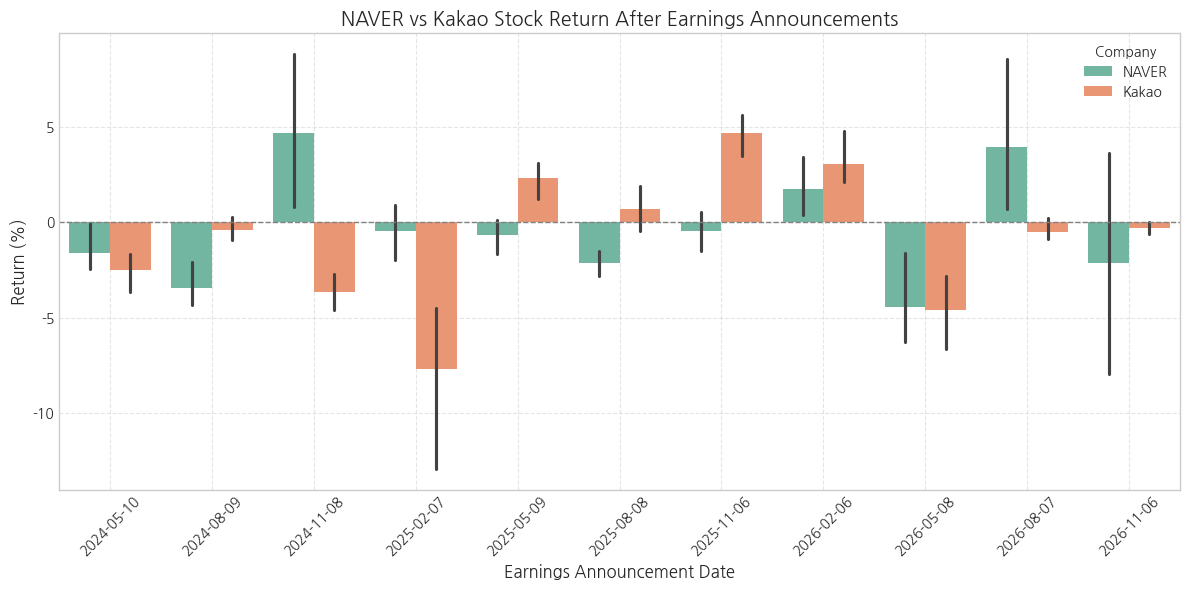

In [43]:
# 1. 라이브러리 설치 및 임포트
!pip install -q finance-datareader

import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 수집 (2년 반: 2024-05-01 ~ 2026-11-16)
start_date = '2024-01-01' # 실적 발표일 전후 인덱스 조회를 위해 여유 있게 설정
end_date = '2026-11-16'

tickers = {'NAVER': '035420', 'Kakao': '035720'}
df_prices = pd.DataFrame()

for name, code in tickers.items():
    df = fdr.DataReader(code, start_date, end_date)
    df_prices[name] = df['Close']

# 3. 주요 실적 발표일 정의 (2024년 1분기 ~ 2026년 3분기 대략적인 공시일 기준)
# ※ 정확한 DART 공시 일자에 맞춰 날짜를 수정하여 정밀 분석할 수 있습니다.
earnings_dates = [
    '2024-05-10', # 24 Q1
    '2024-08-09', # 24 Q2
    '2024-11-08', # 24 Q3
    '2025-02-07', # 24 Q4
    '2025-05-09', # 25 Q1
    '2025-08-08', # 25 Q2
    '2025-11-06', # 25 Q3
    '2026-02-06', # 25 Q4
    '2026-05-08', # 26 Q1
    '2026-08-07', # 26 Q2
    '2026-11-06'  # 26 Q3
]

# 4. 실적 발표일 기준 사후 수익률(T+1, T+3, T+5) 계산 함수
results = []

for edate in earnings_dates:
    # 주가 데이터에 해당 날짜가 존재하는지 확인 (휴장일일 경우 Pandas 2.0+ 호환 방식으로 가장 가까운 영업일 매칭)
    try:
        idx = df_prices.index.get_indexer([pd.to_datetime(edate)], method='nearest')[0]
        if idx == -1:
            continue
    except Exception:
        continue

    # 발표 당일(T), T+1, T+3, T+5 영업일 인덱스 확보
    if idx + 5 >= len(df_prices):
        continue # 데이터 범위 초과 시 제외

    date_T = df_prices.index[idx]
    date_T1 = df_prices.index[idx + 1]
    date_T3 = df_prices.index[idx + 3]
    date_T5 = df_prices.index[idx + 5]

    for name in tickers.keys():
        p_T = df_prices.loc[date_T, name]
        p_T1 = df_prices.loc[date_T1, name]
        p_T3 = df_prices.loc[date_T3, name]
        p_T5 = df_prices.loc[date_T5, name]

        results.append({
            'Earnings_Date': date_T.strftime('%Y-%m-%d'),
            'Company': name,
            'Return_T1': (p_T1 / p_T - 1) * 100,
            'Return_T3': (p_T3 / p_T - 1) * 100,
            'Return_T5': (p_T5 / p_T - 1) * 100
        })

df_results = pd.DataFrame(results)
print("=== 실적 발표일별 단기 주가 수익률 (%) ===")
print(df_results.to_string(index=False))

# 5. 시각화: 발표 후 기간별(T+1, T+3, T+5) 평균 주가 반응 비교
df_melted = df_results.melt(id_vars=['Earnings_Date', 'Company'],
                            value_vars=['Return_T1', 'Return_T3', 'Return_T5'],
                            var_name='Horizon', value_name='Return_%')

plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x='Earnings_Date', y='Return_%', hue='Company', palette='Set2')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('NAVER vs Kakao Stock Return After Earnings Announcements', fontsize=14, fontweight='bold')
plt.xlabel('Earnings Announcement Date', fontsize=12)
plt.ylabel('Return (%)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

=== 최신 재무제표 기준 부채비율 산출 ===
• NAVER 부채비율: 43.98% (총부채: 12,131,482,961,720원, 자기자본: 27,581,956,984,240원)
• Kakao 부채비율: 111.37% (총부채: 12,558,602,529,760원, 자기자본: 11,276,217,552,480원)

=== 2년 반 기간 연환산 수익률 변동성 ===
• NAVER 연환산 변동성: 46.73%
• Kakao 연환산 변동성: 46.38%

=== 재무레버리지(부채비율)와 변동성 요약 테이블 ===
       Debt_Equity_Ratio(%)  Annualized_Volatility(%)
NAVER             43.983402                 46.732275
Kakao            111.372475                 46.376494


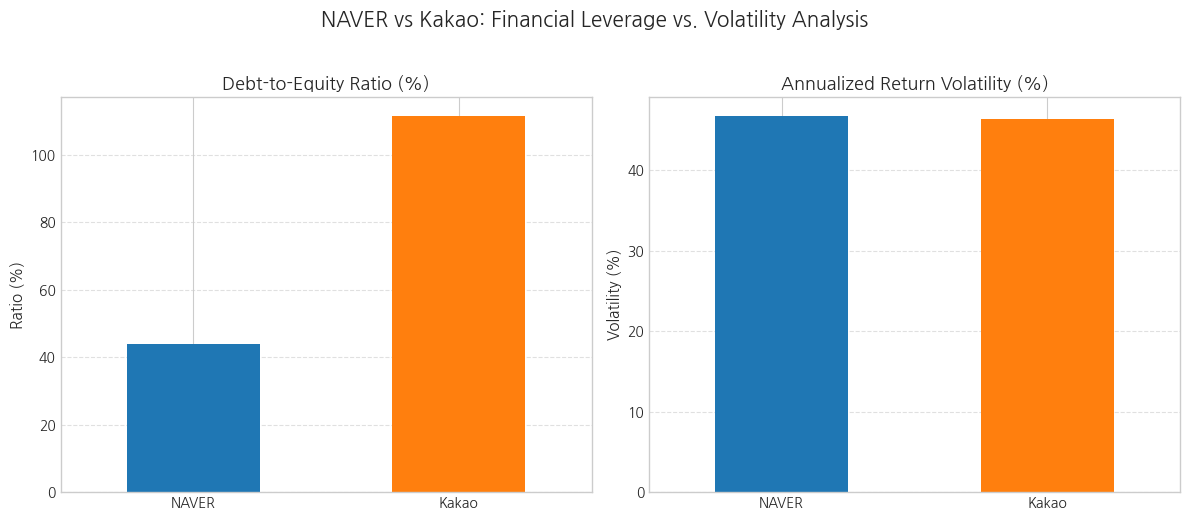

<Figure size 1200x600 with 0 Axes>

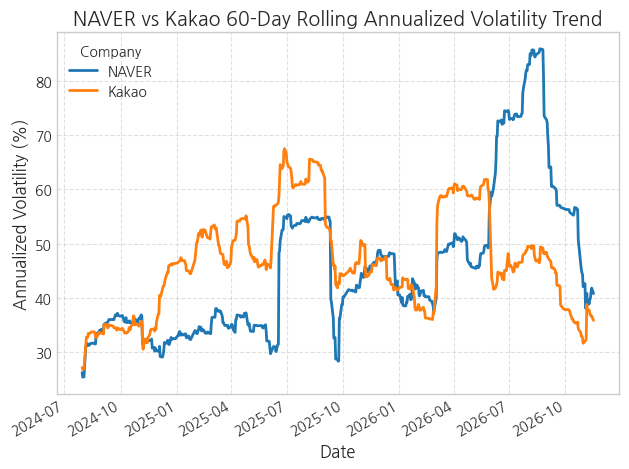

In [44]:
# 1. 필수 라이브러리 설치 및 임포트
!pip install -q finance-datareader yfinance

import FinanceDataReader as fdr
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 부채비율 산출 (yfinance 재무제표 활용)
# 야후파이낸스 티커: NAVER ('035420.KS'), Kakao ('035720.KS')
tickers_yf = {'NAVER': '035420.KS', 'Kakao': '035720.KS'}
debt_ratios = {}

print("=== 최신 재무제표 기준 부채비율 산출 ===")
for name, ticker in tickers_yf.items():
    stock = yf.Ticker(ticker)
    bs = stock.balance_sheet

    # 가장 최근 연간 재무제표 기준 총부채와 자기자본 추출
    # (연결재무제표 기준 Total Liabilities와 Total Stockholder Equity)
    total_liab = bs.loc['Total Liabilities Net Minority Interest'].iloc[0] if 'Total Liabilities Net Minority Interest' in bs.index else bs.loc['Total Liabilities'].iloc[0]
    total_equity = bs.loc['Stockholders Equity'].iloc[0] if 'Stockholders Equity' in bs.index else bs.loc['Total Equity'].iloc[0]

    # 부채비율 (%) = (총부채 / 자기자본) * 100
    d_e_ratio = (total_liab / total_equity) * 100
    debt_ratios[name] = d_e_ratio
    print(f"• {name} 부채비율: {d_e_ratio:.2f}% (총부채: {total_liab:,.0f}원, 자기자본: {total_equity:,.0f}원)")

# 3. 2년 반 주가 데이터 수집 및 연환산 변동성 계산 (2024-05-01 ~ 2026-11-16)
start_date = '2024-05-01'
end_date = '2026-11-16'

tickers_fdr = {'NAVER': '035420', 'Kakao': '035720'}
df_prices = pd.DataFrame()

for name, code in tickers_fdr.items():
    df = fdr.DataReader(code, start_date, end_date)
    df_prices[name] = df['Close']

# 일일 수익률 및 연환산 변동성 계산 (Std * sqrt(252))
df_returns = df_prices.pct_change().dropna()
annual_volatility = df_returns.std() * np.sqrt(252) * 100

print("\n=== 2년 반 기간 연환산 수익률 변동성 ===")
for name, vol in annual_volatility.items():
    print(f"• {name} 연환산 변동성: {vol:.2f}%")

# 4. 부채비율과 변동성 종합 데이터프레임 생성 및 시각화
df_analysis = pd.DataFrame({
    'Debt_Equity_Ratio(%)': [debt_ratios['NAVER'], debt_ratios['Kakao']],
    'Annualized_Volatility(%)': [annual_volatility['NAVER'], annual_volatility['Kakao']]
}, index=['NAVER', 'Kakao'])

print("\n=== 재무레버리지(부채비율)와 변동성 요약 테이블 ===")
print(df_analysis)

# 시각화: 부채비율 vs 변동성 바 차트 비교
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df_analysis['Debt_Equity_Ratio(%)'].plot(kind='bar', ax=axes[0], color=['tab:blue', 'tab:orange'])
axes[0].set_title('Debt-to-Equity Ratio (%)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Ratio (%)', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)
axes[0].tick_params(axis='x', rotation=0)

df_analysis['Annualized_Volatility(%)'].plot(kind='bar', ax=axes[1], color=['tab:blue', 'tab:orange'])
axes[1].set_title('Annualized Return Volatility (%)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Volatility (%)', fontsize=11)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('NAVER vs Kakao: Financial Leverage vs. Volatility Analysis', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 5. 시간 변화에 따른 롤링 변동성(Rolling Volatility) 추이 비교
rolling_vol = df_returns.rolling(window=60).std() * np.sqrt(252) * 100

plt.figure(figsize=(12, 6))
rolling_vol.plot(linewidth=2)
plt.title('NAVER vs Kakao 60-Day Rolling Annualized Volatility Trend', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Annualized Volatility (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

=== NAVER & 카카오 퀀트 분석 데이터 수집 시작 (2024-05-01 ~ 2026-11-16) ===

 📈 [1] 2.5년 기간 누적 수익률 (%)
NAVER    -8.633475
카카오     -33.333333

 🔗 [2] NAVER & 카카오 일별 수익률 상관계수 (동조화)
          NAVER       카카오
NAVER  1.000000  0.573823
카카오    0.573823  1.000000
[오류] NAVER 크롤링 실패: HTTPSConnectionPool(host='companyinfo.stock.naver.com', port=443): Max retries exceeded with url: /v1/company/c1010001.aspx?cmp_cd=035420 (Caused by SSLError(SSLError("bad handshake: SysCallError(-1, 'Unexpected EOF')")))
[오류] 카카오 크롤링 실패: HTTPSConnectionPool(host='companyinfo.stock.naver.com', port=443): Max retries exceeded with url: /v1/company/c1010001.aspx?cmp_cd=035720 (Caused by SSLError(SSLError("bad handshake: SysCallError(-1, 'Unexpected EOF')")))

 📊 [3] 재무 안정성 및 밸류에이션 지표 요약
  종목명 부채비율(%) PBR(배) PER(배) ROE(%)
NAVER     N/A    N/A    N/A    N/A
  카카오     N/A    N/A    N/A    N/A


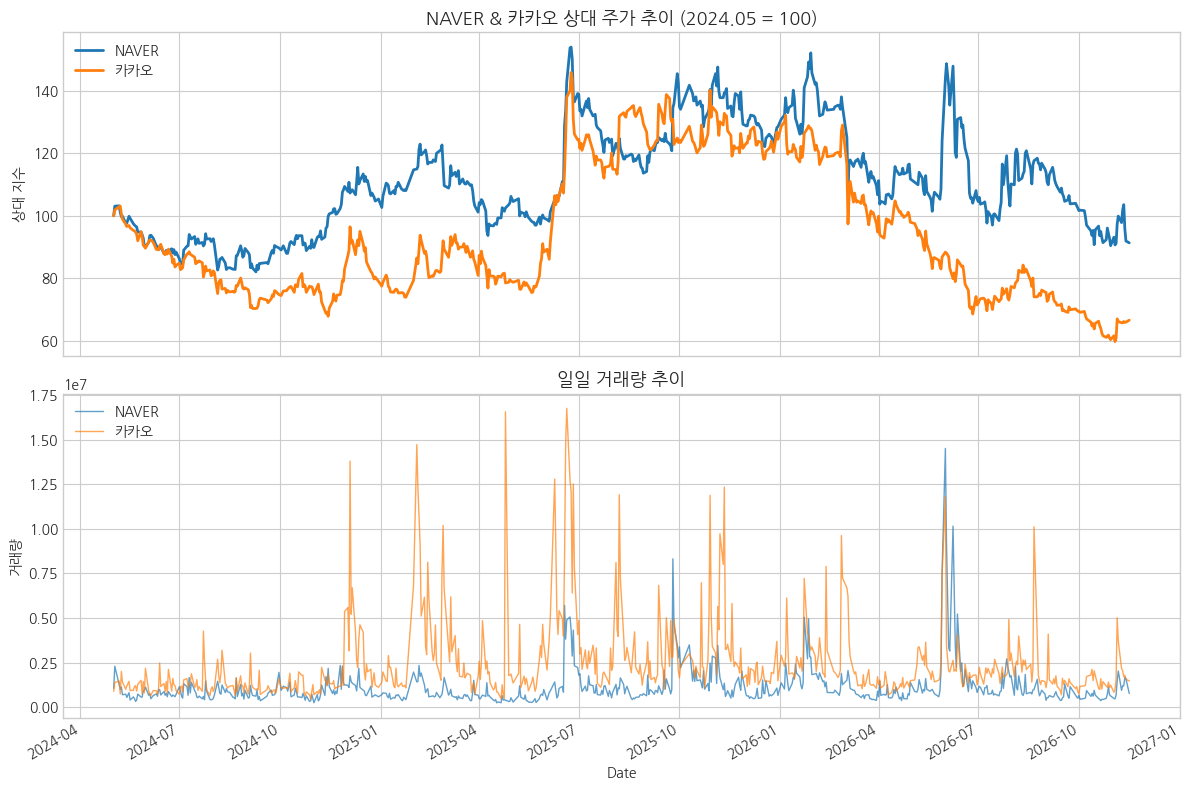


💾 시각화 차트 저장 완료: naver_kakao_quant_analysis.png


In [46]:
from __future__ import annotations
import pandas as pd
import numpy as np
import FinanceDataReader as fdr
import requests
from requests.adapters import HTTPAdapter
from urllib3.util import create_urllib3_context
from io import StringIO
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 0. 코랩/리눅스 환경 한글 폰트 설정
# ==========================================
import subprocess
from pathlib import Path
import matplotlib.font_manager as fm

subprocess.run(['apt-get', 'update'], stdout=subprocess.DEVNULL)
subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], stdout=subprocess.DEVNULL)

nanum_font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if Path(nanum_font_path).exists():
    fe = fm.FontEntry(fname=nanum_font_path, name='NanumGothic')
    fm.fontManager.ttflist.insert(0, fe)
    plt.rcParams['font.family'] = 'NanumGothic'

plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 1. 네이버 금융 SSL 오류 우회용 어댑터 클래스
# ==========================================
class SSLAdapter(HTTPAdapter):
    def init_poolmanager(self, *args, **kwargs):
        context = create_urllib3_context()
        context.set_ciphers('DEFAULT:@SECLEVEL=1')
        kwargs['ssl_context'] = context
        return super().init_poolmanager(*args, **kwargs)

# ==========================================
# 2. 분석 대상 유니버스 정의 (NAVER, 카카오)
# ==========================================
tickers = {
    "035420": "NAVER",
    "035720": "카카오"
}

start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== NAVER & 카카오 퀀트 분석 데이터 수집 시작 ({start_date} ~ {end_date}) ===")

# --- [파트 A] 주가 수익률, 거래량, 동조화(상관관계) 분석 ---
price_data = {}
volume_data = {}

for code, name in tickers.items():
    df = fdr.DataReader(code, start_date, end_date)
    price_data[name] = df['Close']
    volume_data[name] = df['Volume']

df_price = pd.DataFrame(price_data)
df_volume = pd.DataFrame(volume_data)

# 1) 기간 누적 수익률 (%) 계산
cum_returns = (df_price.iloc[-1] / df_price.iloc[0] - 1) * 100
print("\n" + "="*50)
print(" 📈 [1] 2.5년 기간 누적 수익률 (%)")
print("="*50)
print(cum_returns.to_string())

# 2) 일별 수익률 및 상관관계 (동조화 분석)
df_returns = df_price.pct_change().dropna()
correlation_matrix = df_returns.corr()
print("\n" + "="*50)
print(" 🔗 [2] NAVER & 카카오 일별 수익률 상관계수 (동조화)")
print("="*50)
print(correlation_matrix.to_string())

# --- [파트 B] 재무건전성(부채비율) 및 밸류에이션(PBR·PER·ROE) 크롤링 ---
def fetch_fundamental_metrics(code: str, name: str) -> dict:
    url = f"https://companyinfo.stock.naver.com/v1/company/c1010001.aspx?cmp_cd={code}"
    session = requests.Session()
    session.mount("https://", SSLAdapter())
    headers = {'User-Agent': 'Mozilla/5.0'}

    try:
        res = session.get(url, headers=headers, timeout=10)
        res.raise_for_status()
        tables = pd.read_html(StringIO(res.text))

        df_fin = None
        for t in tables:
            t_str = "".join(str(t.values))
            if "부채비율" in t_str or "PBR" in t_str or "PER" in t_str:
                df_fin = t
                break

        metrics = {"종목명": name, "부채비율(%)": "N/A", "PBR(배)": "N/A", "PER(배)": "N/A", "ROE(%)": "N/A"}
        if df_fin is not None:
            for _, row in df_fin.iterrows():
                text = str(row.iloc[0])
                val = row.iloc[-2] if len(row) > 1 else "N/A"
                if "부채비율" in text: metrics["부채비율(%)"] = val
                elif "PBR" in text: metrics["PBR(배)"] = val
                elif "PER" in text: metrics["PER(배)"] = val
                elif "ROE" in text: metrics["ROE(%)"] = val
        return metrics
    except Exception as e:
        print(f"[오류] {name} 크롤링 실패: {e}")
        return {"종목명": name, "부채비율(%)": "N/A", "PBR(배)": "N/A", "PER(배)": "N/A", "ROE(%)": "N/A"}

fundamental_results = [fetch_fundamental_metrics(code, name) for code, name in tickers.items()]
df_fundamental = pd.DataFrame(fundamental_results)

print("\n" + "="*50)
print(" 📊 [3] 재무 안정성 및 밸류에이션 지표 요약")
print("="*50)
print(df_fundamental.to_string(index=False))

# CSV 파일 저장
df_fundamental.to_csv("naver_kakao_fundamentals.csv", index=False, encoding="utf-8-sig")

# --- [파트 C] 시각화 (상대 주가 추이 및 거래량) ---
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# 1) 상대 주가 추이 (시작점 = 100 기준화)
df_price_norm = (df_price / df_price.iloc[0]) * 100
df_price_norm.plot(ax=axes[0], linewidth=2)
axes[0].set_title("NAVER & 카카오 상대 주가 추이 (2024.05 = 100)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("상대 지수")
axes[0].legend(loc="upper left")

# 2) 일일 거래량 추이
df_volume.plot(ax=axes[1], alpha=0.7, linewidth=1)
axes[1].set_title("일일 거래량 추이", fontsize=13, fontweight='bold')
axes[1].set_ylabel("거래량")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.savefig("naver_kakao_quant_analysis.png", dpi=300)
plt.show()
print("\n💾 시각화 차트 저장 완료: naver_kakao_quant_analysis.png")